# Лабораторная работа №5
## Исследование градиентного бустинга

**Цель:** повторить пункты 2–4 первой работы: бейзлайны sklearn, проверка улучшений на CV, собственный градиентный бустинг для классификации и регрессии, перенос выбранных улучшений и сравнение результатов.

Условия совпадают с предыдущими работами:
- [Steam Game Hits](https://www.kaggle.com/datasets/vedauv/what-makes-a-steam-game-a-hit-8000-games): цель `hit`; основная метрика **Average Precision (AP)**. Дополнительно F1, precision, recall, balanced accuracy, ROC AUC, accuracy. Порог вероятности >0.5; при равенстве выбираем 0. AP оценивает ранжирование редкого класса без привязки к одному порогу.
- [Video Games Sales](https://www.kaggle.com/datasets/ulrikthygepedersen/video-games-sales): цель `global_sales` в **миллионах копий**; основная метрика **MAE**, дополнительные — RMSE и R². MAE интерпретируется в единицах продаж, RMSE сильнее выделяет крупные ошибки.

Steam-набор **синтетический**: `hit=1` — верхние 20% по выручке, поэтому выводы относятся к генератору. В признаках нет выручки, владельцев, отзывов и результатов после релиза. Wishlist — дорелизный по описанию автора; доступность остальных характеристик до релиза предполагается в учебном сценарии. Для продаж исключены ранг и региональные продажи, почти раскрывающие ответ. Название используется только при группировке. Накопленные продажи не имеют общего горизонта наблюдения.

Разбиения прежние: seed=42, 80/20, стратификация Steam, группировка продаж по названию игры, 3-fold CV внутри train. Все преобразователи обучаются внутри Pipeline на train-fold. Тест не участвует в выборе решений. Встроенную раннюю остановку со случайной validation-частью не используем: число итераций выбирается по CV, с сохранением групп для продаж.

Ноутбук самодостаточен, запускается из корня проекта и не требует выполнения других работ. Пояснения находятся в Markdown, без комментариев через `#` внутри кода. Дополнительно сохраняются только `cv_experiments.csv` и `test_metrics.csv` в `results/research-5/`; графики и остальные результаты остаются в ноутбуке.

### Импорт и воспроизводимость
Используем существующие зависимости, фиксированный seed и два потока численных библиотек. CV выполняется последовательно (`n_jobs=1`), без фоновых процессов joblib.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
from pathlib import Path
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold, GroupKFold, GridSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from threadpoolctl import threadpool_limits
SEED = 42
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Откройте ноутбук из корня проекта"
RESULTS = ROOT / "results/research-5"
RESULTS.mkdir(parents=True, exist_ok=True)
print({"Python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

{'Python': '3.14.8', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Подготовка данных и неизменные разбиения
Повторяем очистку и белые списки признаков предыдущих работ. Версии одной игры не пересекают train/test и CV-fold в задаче продаж. Пропуски признаков заполняются только внутри Pipeline.

In [2]:
steam = pd.read_csv(ROOT / "data/steam/steam_game_hits.csv")
sales = pd.read_csv(ROOT / "data/sales/video_games_sales.csv")
steam = steam.drop_duplicates().dropna(subset=["hit"]).reset_index(drop=True)
sales = sales.drop_duplicates().dropna(subset=["global_sales", "name"]).copy()
sales = sales.loc[np.isfinite(sales.global_sales) & (sales.global_sales >= 0)].reset_index(drop=True)
steam_num = ["release_year", "is_indie", "team_size", "price_usd", "has_multiplayer",
             "early_access", "controller_support", "languages_supported", "file_size_gb",
             "wishlists_k", "trailer_views_k"]
steam_cat = ["genre"]
sales_num, sales_cat = ["year"], ["platform", "genre", "publisher"]
Xc, yc = steam[steam_num + steam_cat].copy(), steam.hit.astype(int)
Xr, yr = sales[sales_num + sales_cat].copy(), sales.global_sales.astype(float)
groups = sales.name.str.normalize("NFKC").str.strip().str.casefold()
ic_train, ic_test = train_test_split(np.arange(len(Xc)), test_size=0.2,
                                     stratify=yc, random_state=SEED)
ir_train, ir_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                            random_state=SEED).split(Xr, yr, groups))
Xc_train, Xc_test, yc_train, yc_test = Xc.iloc[ic_train], Xc.iloc[ic_test], yc.iloc[ic_train], yc.iloc[ic_test]
Xr_train, Xr_test, yr_train, yr_test = Xr.iloc[ir_train], Xr.iloc[ir_test], yr.iloc[ir_train], yr.iloc[ir_test]
g_train, g_test = groups.iloc[ir_train], groups.iloc[ir_test]
assert not set(g_train) & set(g_test)
cv_c = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xc_train, yc_train))
cv_r = list(GroupKFold(3).split(Xr_train, yr_train, g_train))
for a, b in cv_r:
    assert not set(g_train.iloc[a]) & set(g_train.iloc[b])
display(pd.DataFrame({"Задача": ["Классификация", "Регрессия"],
    "train": [len(ic_train), len(ir_train)], "test": [len(ic_test), len(ir_test)]}))
print("Доля hit в train/test:", round(yc_train.mean(), 3), round(yc_test.mean(), 3))

,Задача,train,test
0,Классификация,6400,1600
1,Регрессия,13272,3326


Доля hit в train/test: 0.2 0.2


## 2. Создание бейзлайна и оценка качества
### 2a. Модели sklearn
Используем `GradientBoostingClassifier(loss="log_loss")` и `GradientBoostingRegressor(loss="squared_error")`. Явно задаём 50 деревьев, скорость обучения 0.1, глубину 2, минимум 5 строк в листе, все признаки и все строки на каждой итерации. Это компактный бейзлайн для воспроизводимого эксперимента, а не все настройки sklearn по умолчанию.

В отличие от леса деревья обучаются **последовательно**: новое дерево корректирует текущий прогноз. Для log-loss модель складывает поправки к логиту вероятности; для регрессии — поправки к числовому прогнозу.

Числа заполняем медианой, категории — наиболее частым значением и one-hot; неизвестные категории кодируются нулями. Масштабирование не требуется деревьям. Библиотечный критерий разбиения оставляем по умолчанию: в проверенной sklearn 1.9.1 для базовых деревьев используется squared_error; формулы сверены с установленным `sklearn.ensemble._gb`. В других версиях реализация и численные детали могут отличаться.

In [3]:
def prep(task, engineered=False):
    num = list(steam_num if task == "c" else sales_num)
    cat = list(steam_cat if task == "c" else sales_cat)
    if engineered:
        if task == "c":
            num += ["wishlist_per_team", "wishlist_trailer_ratio", "wishlist_price"]
        else:
            cat += ["platform_genre", "decade"]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                     min_frequency=0.01 if engineered else None))]), cat)
    ], sparse_threshold=0)

def pipeline(task, model, engineered=False):
    steps = [("features", Features(task))] if engineered else []
    return Pipeline(steps + [("prep", prep(task, engineered)), ("model", model)])

def estimator(task, **params):
    cls = GradientBoostingClassifier if task == "c" else GradientBoostingRegressor
    settings = dict(n_estimators=50, learning_rate=0.1, max_depth=2, min_samples_leaf=5,
                    subsample=1., random_state=SEED)
    settings.update(params)
    return cls(**settings)

base_c = pipeline("c", estimator("c")).fit(Xc_train, yc_train)
base_r = pipeline("r", estimator("r")).fit(Xr_train, yr_train)
print("Исходные модели градиентного бустинга обучены.")

Исходные модели градиентного бустинга обучены.


### 2b. Тестовые метрики, train-метрики и Dummy
Dummy задаёт ориентир: доля классов для AP и медиана продаж для MAE. Показываем также качество на train и число итераций. Разрыв train/test служит диагностикой переобучения, а не основанием настройки по тесту. Градиентный бустинг регрессии может давать отрицательные прогнозы; не обрезаем их и выводим количество отдельно, одинаково для sklearn и NumPy.

In [4]:
rows, predictions = [], {}
def evaluate(name, task, model):
    X, y = (Xc_test, yc_test) if task == "c" else (Xr_test, yr_test)
    start = time.perf_counter()
    if task == "c":
        prob = model.predict_proba(X)[:, 1]
        pred = (prob > 0.5).astype(int)
        metrics = {"AP": average_precision_score(y, prob), "ROC_AUC": roc_auc_score(y, prob),
            "F1": f1_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "Balanced_accuracy": balanced_accuracy_score(y, pred),
            "Accuracy": accuracy_score(y, pred)}
        predictions[(task, name)] = (pred, prob)
    else:
        pred = model.predict(X)
        metrics = {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),
                   "R2": r2_score(y, pred), "negative_predictions": int((pred < 0).sum())}
        predictions[(task, name)] = pred
    rows.append({"task": task, "model": name, **metrics, "predict_seconds": time.perf_counter() - start})
    return pd.DataFrame([rows[-1]])


dummy_c = DummyClassifier(strategy="prior").fit(Xc_train, yc_train)
dummy_r = DummyRegressor(strategy="median").fit(Xr_train, yr_train)
for name, task, model in [("Dummy", "c", dummy_c), ("Dummy", "r", dummy_r),
                          ("sklearn baseline", "c", base_c), ("sklearn baseline", "r", base_r)]:
    display(evaluate(name, task, model))
for task, model, X, y in [("c", base_c, Xc_train, yc_train), ("r", base_r, Xr_train, yr_train)]:
    score = average_precision_score(y, model.predict_proba(X)[:, 1]) if task == "c" else mean_absolute_error(y, model.predict(X))
    print(task, "Train AP" if task == "c" else "Train MAE", score,
          "итераций:", model.named_steps["model"].n_estimators_)

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.2,0.5,0.0,0.0,0.0,0.5,0.8,0.035851


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,Dummy,0.456185,1.616683,-0.051272,0,0.002656


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn baseline,0.704186,0.896987,0.586271,0.721461,0.49375,0.723047,0.860625,0.039116


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,sklearn baseline,0.533683,1.490779,0.106094,0,0.038711


c Train AP 0.7163960658472082 итераций: 50


r Train MAE 0.528490458893953 итераций: 50


## 3. Улучшение бейзлайна
### 3a. Гипотезы
1. **H1 — подготовка и взаимодействия.** Объединяем редкие категории (<1% train-fold). Для Steam добавляем wishlist/размер команды, wishlist/просмотры и wishlist×цена; для продаж — платформа–жанр и десятилетие. Все признаки дорелизные в принятом сценарии. Проверяем эффект при неизменных настройках бустинга.
2. **H2 — скорость, число и сложность деревьев.** Проверяем четыре заранее заданные конфигурации: (learning_rate, n_estimators, max_depth, min_samples_leaf) = (0.05,100,2,10), (0.1,100,2,10), (0.05,100,3,25), (0.1,50,3,25). Небольшой шаг требует больше итераций, а глубина определяет сложность взаимодействий. Сетка ограничена для разумного времени запуска.
3. **H3 — стохастический бустинг.** Для лучшей конфигурации H2 проверяем `subsample=0.75`: на каждой итерации случайно выбираем строки **без возвращения**. Это регуляризация, а не bootstrap случайного леса. Подвыборки формируются только внутри train-fold; CV-валидация по-прежнему целиком отделена.
4. **H4 — логарифм цели продаж.** Для log1p продаж проверяем те же четыре конфигурации H2 с expm1 на выходе. CV и тест оцениваем в исходных миллионах копий. Это меняет обучающую ошибку; MAE может улучшиться при ухудшении RMSE. Обратное преобразование не даёт несмещённое среднее продаж.

Масштабирование и монотонное логарифмирование входных признаков не добавляют деревьям новых порядков разбиения, поэтому не проверяются как отдельные улучшения. Используем бинарную log-loss и squared_error; другие функции потерь и библиотеки XGBoost/LightGBM в эту работу не входят.

### 3b. Признаки и анализ train
Преобразователь не использует целевую переменную. Смотрим распределения только обучающей части.

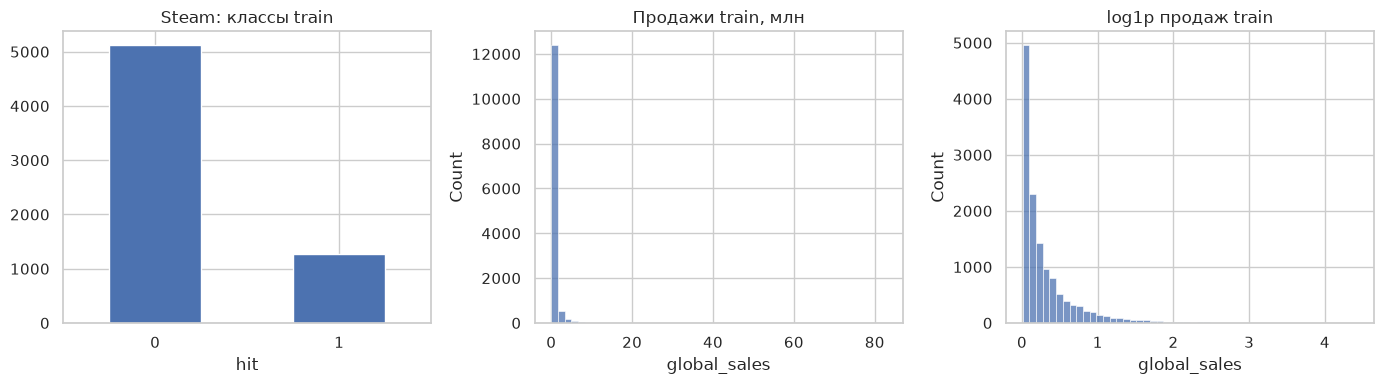

,Категорий в train
platform,30
genre,12
publisher,533


In [5]:
class Features(TransformerMixin, BaseEstimator):
    def __init__(self, task="c"):
        self.task = task
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        out = X.copy()
        if self.task == "c":
            out["wishlist_per_team"] = out.wishlists_k / (out.team_size + 1)
            out["wishlist_trailer_ratio"] = out.wishlists_k / (out.trailer_views_k + 1)
            out["wishlist_price"] = out.wishlists_k * out.price_usd
        else:
            out["platform_genre"] = out.platform.fillna("unknown") + " / " + out.genre.fillna("unknown")
            out["decade"] = ((out.year // 10) * 10).astype("Int64").astype("string").fillna("unknown").astype(object)
        return out

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
yc_train.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title="Steam: классы train")
sns.histplot(yr_train, bins=50, ax=axes[1]); axes[1].set_title("Продажи train, млн")
sns.histplot(np.log1p(yr_train), bins=50, ax=axes[2]); axes[2].set_title("log1p продаж train")
plt.tight_layout(); plt.show()
display(Xr_train[sales_cat].nunique().rename("Категорий в train").to_frame())

### 3b–3c. Проверка гипотез и выбор по CV
Сначала сравниваем H0 и H1 при одинаковых настройках, затем для H2 выбираем лучшую из этих двух подготовок по CV. H3 меняет только долю строк у лучшей H2-модели. H4 использует ту же подготовку и сетку H2, изменяя цель. Это последовательное исследование, а не исчерпывающий поиск всех комбинаций.

Все варианты оцениваются на одинаковых fold. `score` — AP или **−MAE**, больше — лучше. `std` — разброс по fold, не доверительный интервал. Финальный выбор включает H0: улучшение не гарантировано. Тест используется только после фиксации выбора; после его просмотра параметры не меняются.

In [6]:
candidates, experiments, searches = {"c": {}, "r": {}}, [], {}
settings = [(0.05, 100, 2, 10), (0.1, 100, 2, 10), (0.05, 100, 3, 25), (0.1, 50, 3, 25)]
grid = [{"model__learning_rate": [rate], "model__n_estimators": [number],
         "model__max_depth": [depth], "model__min_samples_leaf": [leaf]}
        for rate, number, depth, leaf in settings]
for task, X, y, folds, scoring in [("c", Xc_train, yc_train, cv_c, "average_precision"),
                                  ("r", Xr_train, yr_train, cv_r, "neg_mean_absolute_error")]:
    preparation = {}
    for name, engineered in [("H0 baseline", False), ("H1 features", True)]:
        model = pipeline(task, estimator(task), engineered)
        scores = cross_val_score(model, X, y, cv=folds, scoring=scoring, n_jobs=1)
        candidates[task][name] = model
        preparation[engineered] = scores.mean()
        experiments.append({"task": task, "experiment": name, "score": scores.mean(), "std": scores.std()})
    engineered = preparation[True] > preparation[False]
    print(task, "Подготовка для H2–H4:", "расширенная" if engineered else "исходная")
    model = pipeline(task, estimator(task), engineered)
    search = GridSearchCV(model, grid, cv=folds, scoring=scoring, n_jobs=1, refit=True, error_score="raise")
    search.fit(X, y)
    searches[(task, "H2 tuned")] = search
    candidates[task]["H2 tuned"] = search.best_estimator_
    experiments.append({"task": task, "experiment": "H2 tuned", "score": search.best_score_,
                        "std": search.cv_results_["std_test_score"][search.best_index_]})
    print(task, "H2", search.best_params_)
    display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]])
    stochastic = clone(search.best_estimator_).set_params(model__subsample=0.75)
    scores = cross_val_score(stochastic, X, y, cv=folds, scoring=scoring, n_jobs=1)
    candidates[task]["H3 stochastic"] = stochastic
    experiments.append({"task": task, "experiment": "H3 stochastic", "score": scores.mean(), "std": scores.std()})
    if task == "r":
        log_model = TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)
        log_grid = [{"regressor__"+k: v for k, v in params.items()} for params in grid]
        search = GridSearchCV(log_model, log_grid, cv=folds, scoring=scoring, n_jobs=1, refit=True, error_score="raise")
        search.fit(X, y)
        searches[(task, "H4 log target")] = search
        candidates[task]["H4 log target"] = search.best_estimator_
        experiments.append({"task": task, "experiment": "H4 log target", "score": search.best_score_,
                            "std": search.cv_results_["std_test_score"][search.best_index_]})
        print(task, "H4", search.best_params_)
        display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]])
cv_table = pd.DataFrame(experiments)
display(cv_table)
cv_table.to_csv(RESULTS / "cv_experiments.csv", index=False)
for task in ["c", "r"]:
    tab = cv_table[cv_table.task == task].set_index("experiment")
    reference = tab.loc[["H0 baseline", "H1 features"], "score"].idxmax()
    pairs = [("H1 features", "H0 baseline"), ("H2 tuned", reference), ("H3 stochastic", "H2 tuned")]
    if task == "r": pairs.append(("H4 log target", "H2 tuned"))
    for name, previous in pairs:
        gain = tab.loc[name, "score"] - tab.loc[previous, "score"]
        print(task, name, "минус", previous, round(gain, 6), "— поддержана по среднему CV" if gain > 0 else "— не поддержана")

c Подготовка для H2–H4: расширенная


c H2 {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 25, 'model__n_estimators': 100}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__learning_rate': 0.05, 'model__max_dep...",0.686914,0.020034,4
1,"{'model__learning_rate': 0.1, 'model__max_dept...",0.689378,0.018312,3
2,"{'model__learning_rate': 0.05, 'model__max_dep...",0.689781,0.017619,1
3,"{'model__learning_rate': 0.1, 'model__max_dept...",0.689464,0.017666,2


r Подготовка для H2–H4: расширенная


r H2 {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 10, 'model__n_estimators': 100}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__learning_rate': 0.05, 'model__max_dep...",-0.531540,0.009419,4
1,"{'model__learning_rate': 0.1, 'model__max_dept...",-0.518549,0.008013,1
2,"{'model__learning_rate': 0.05, 'model__max_dep...",-0.521858,0.007411,3
3,"{'model__learning_rate': 0.1, 'model__max_dept...",-0.521360,0.007294,2


r H4 {'regressor__model__learning_rate': 0.1, 'regressor__model__max_depth': 2, 'regressor__model__min_samples_leaf': 10, 'regressor__model__n_estimators': 100}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'regressor__model__learning_rate': 0.05, 'reg...",-0.464335,0.015268,4
1,"{'regressor__model__learning_rate': 0.1, 'regr...",-0.455215,0.014777,1
2,"{'regressor__model__learning_rate': 0.05, 'reg...",-0.456409,0.015098,3
3,"{'regressor__model__learning_rate': 0.1, 'regr...",-0.455959,0.015176,2


,task,experiment,score,std
0,c,H0 baseline,0.683695,0.020727
1,c,H1 features,0.685081,0.019640
2,c,H2 tuned,0.689781,0.017619
3,c,H3 stochastic,0.692018,0.021192
4,r,H0 baseline,-0.533425,0.010066
5,r,H1 features,-0.530175,0.010732
6,r,H2 tuned,-0.518549,0.008013
7,r,H3 stochastic,-0.523453,0.005581
8,r,H4 log target,-0.455215,0.014777


c H1 features минус H0 baseline 0.001386 — поддержана по среднему CV
c H2 tuned минус H1 features 0.0047 — поддержана по среднему CV
c H3 stochastic минус H2 tuned 0.002237 — поддержана по среднему CV
r H1 features минус H0 baseline 0.003249 — поддержана по среднему CV
r H2 tuned минус H1 features 0.011626 — поддержана по среднему CV
r H3 stochastic минус H2 tuned -0.004904 — не поддержана
r H4 log target минус H2 tuned 0.063334 — поддержана по среднему CV


### 3d–3g. Обучение выбранных моделей и сравнение с пунктом 2
Фиксируем лучшую конфигурацию по CV, обучаем на всём train и оцениваем на прежнем тесте. Положительный выигрыш ниже означает рост AP или снижение MAE. Успех по основной метрике не означает улучшения всех дополнительных.

In [7]:
selected, improved = {}, {}
for task, X, y, metric in [("c", Xc_train, yc_train, "AP"), ("r", Xr_train, yr_train, "MAE")]:
    ranking = cv_table[cv_table.task == task].sort_values("score", ascending=False, kind="stable")
    selected[task] = ranking.iloc[0].experiment
    improved[task] = clone(candidates[task][selected[task]]).fit(X, y)
    print(task, "Выбрано:", selected[task])
    display(evaluate("sklearn improved", task, improved[task]))
    table = pd.DataFrame(rows).query("task == @task").set_index("model")
    a, b = table.loc["sklearn baseline", metric], table.loc["sklearn improved", metric]
    gain = b-a if task == "c" else a-b
    display(Markdown(f"**Вывод пункта 3 ({task}):** {metric}: {a:.5f} → {b:.5f}, выигрыш {gain:+.5f}. "
                     + ("Улучшение подтвердилось на тесте." if gain > 0 else "Улучшение на тесте не подтверждено.")))

c Выбрано: H3 stochastic


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn improved,0.713003,0.900522,0.610413,0.7173,0.53125,0.739453,0.864375,0.031339


**Вывод пункта 3 (c):** AP: 0.70419 → 0.71300, выигрыш +0.00882. Улучшение подтвердилось на тесте.

r Выбрано: H4 log target


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,sklearn improved,0.448553,1.511089,0.081572,0,0.043229


**Вывод пункта 3 (r):** MAE: 0.53368 → 0.44855, выигрыш +0.08513. Улучшение подтвердилось на тесте.

## 4. Самостоятельная имплементация
### 4a. Базовое регрессионное дерево CART
В обеих задачах базовыми моделями бустинга служат **регрессионные деревья** на вещественных антиградиентах. Для каждого непостоянного признака проверяем пороги между различными значениями, выбираем максимальное уменьшение квадратичной ошибки. Кумулятивные суммы позволяют оценить пороги после сортировки; бинарные one-hot столбцы обрабатываем без сортировки. Значение листа при обучении дерева — средний антиградиент.

Разбиения ограничиваются глубиной и числом строк в листе. При равных выигрышах выбирается первый признак и порог; sklearn может иначе разрешать ничьи. Признаки приводим к float32, суммы считаем в float64. Стек заданий не удерживает временные матрицы родителей в рекурсивных вызовах. Готовые деревья sklearn внутри собственной реализации не вызываются.

In [8]:
class NumpyRegressionTree(RegressorMixin, BaseEstimator):
    def __init__(self, max_depth=2, min_samples_leaf=5):
        self.max_depth, self.min_samples_leaf = max_depth, min_samples_leaf
    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float32, y_numeric=True)
        if not isinstance(self.max_depth, (int, np.integer)) or self.max_depth < 1:
            raise ValueError("max_depth должно быть положительным целым")
        if not isinstance(self.min_samples_leaf, (int, np.integer)) or self.min_samples_leaf < 1:
            raise ValueError("min_samples_leaf должно быть положительным целым")
        self.n_features_in_ = X.shape[1]
        self.nodes_ = []
        pending = [(np.arange(len(y)), 0, None, None)]
        while pending:
            ids, depth, parent, side = pending.pop()
            values, target = X[ids], np.asarray(y[ids], dtype=float)
            mean = target.mean()
            centered = target - mean
            index = len(self.nodes_)
            node = {"feature": -1, "value": mean, "depth": depth, "n_samples": len(ids)}
            self.nodes_.append(node)
            if parent is not None: self.nodes_[parent][side] = index
            if depth >= self.max_depth or len(ids) < 2*self.min_samples_leaf or np.mean(centered**2) <= 1e-14:
                continue
            best_score, best = -np.inf, None
            total = centered.sum()
            for feature in np.flatnonzero(np.ptp(values, axis=0) > 1e-7):
                column = values[:, feature]
                low, high = column.min(), column.max()
                if np.all((column == low) | (column == high)):
                    left = column == low
                    count = int(left.sum())
                    if min(count, len(ids)-count) < self.min_samples_leaf:
                        continue
                    counts = np.array([count])
                    sums = np.array([centered[left].sum()])
                    thresholds = np.array([float(low)/2 + float(high)/2])
                else:
                    order = np.argsort(column, kind="stable")
                    ordered = column[order]
                    positions = np.flatnonzero(np.diff(ordered) > 1e-7)
                    positions = positions[(positions+1 >= self.min_samples_leaf) & (len(ids)-positions-1 >= self.min_samples_leaf)]
                    if not len(positions): continue
                    counts = positions+1
                    sums = np.cumsum(centered[order], dtype=float)[positions]
                    thresholds = ordered[positions].astype(float)/2 + ordered[positions+1].astype(float)/2
                scores = (sums**2/counts + (total-sums)**2/(len(ids)-counts))/len(ids)
                choice = int(np.argmax(scores))
                if scores[choice] > best_score + 1e-12:
                    best_score = float(scores[choice])
                    best = (int(feature), float(thresholds[choice]))
            if best is None: continue
            feature, threshold = best
            left = values[:, feature] <= threshold
            node.update(feature=feature, threshold=threshold)
            pending.append((ids[~left], depth+1, index, "right"))
            pending.append((ids[left], depth+1, index, "left"))
        return self
    def apply(self, X):
        check_is_fitted(self, "nodes_")
        X = check_array(X, dtype=np.float32)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        leaves = np.zeros(len(X), dtype=int)
        pending = [(0, np.arange(len(X)))]
        while pending:
            index, ids = pending.pop()
            node = self.nodes_[index]
            if node["feature"] < 0:
                leaves[ids] = index
            else:
                left = X[ids, node["feature"]] <= node["threshold"]
                if left.any(): pending.append((node["left"], ids[left]))
                if (~left).any(): pending.append((node["right"], ids[~left]))
        return leaves
    def predict(self, X):
        leaves = self.apply(X)
        return np.array([node["value"] for node in self.nodes_])[leaves]

### 4a. Антиградиенты, shrinkage и обновление листьев
**Регрессия:** F₀=mean(y), rᵢ=yᵢ−Fᵢ. Обучаем дерево на r и обновляем F←F+η·tree(X). Это градиентный бустинг для половины квадратичной ошибки; в истории для интерпретации записываем MSE без множителя 1/2.

**Бинарная классификация:** F₀=log(p₀/(1−p₀)), p=σ(F), r=y−p. Обучаем регрессионное дерево на r. Затем для каждого листа R выполняем ньютоновскую коррекцию γ=Σᵣ(y−p)/Σᵣp(1−p) и обновляем F←F+η·γ. Суммы при subsample берутся только по строкам текущей подвыборки. Это важное отличие от простого усреднения антиградиентов листа. При почти нулевом знаменателе задаём γ=0 для устойчивости. Вероятность вычисляем устойчивой сигмоидой через logaddexp; log-loss — через logaddexp без экспоненты большого положительного числа.

При subsample<1 выбираем floor(subsample·n) строк без возвращения, дерево обучается на них, а прогноз обновляется для **всего** train. История train-loss считается на полном train в обучающей шкале (для log1p цели — в логарифмической). На стохастических шагах она не обязана монотонно уменьшаться. Предсказание складывает начальную константу и поправки всех деревьев; поддерживаются промежуточные прогнозы по итерациям.

Реализованы бинарная log-loss, squared_error, shrinkage, ограничение глубины/листа и подвыборка строк. Не реализованы произвольные веса, многоклассовый бустинг и автоматическая early stopping; они не используются в сравнении. Построение T деревьев примерно в T раз дороже одного CART; предсказание проходит все T деревьев. Численные допуски, ничьи разбиений и генератор подвыборок могут давать отличия от sklearn при одинаковых параметрах.

In [9]:
class NumpyGradientBoosting(BaseEstimator):
    def __init__(self, n_estimators=50, learning_rate=0.1, max_depth=2, min_samples_leaf=5,
                 subsample=1., random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.subsample = subsample
        self.random_state = random_state
    def _loss(self, y, raw):
        if self._classification:
            return np.mean(np.logaddexp(0, raw) - y*raw)
        return np.mean((y-raw)**2)
    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float32, y_numeric=not self._classification)
        if not isinstance(self.n_estimators, (int, np.integer)) or self.n_estimators < 1:
            raise ValueError("n_estimators должно быть положительным целым")
        if not np.isfinite(self.learning_rate) or self.learning_rate <= 0:
            raise ValueError("learning_rate должно быть конечным и положительным")
        if not np.isfinite(self.subsample) or not 0 < self.subsample <= 1:
            raise ValueError("subsample должно принадлежать (0, 1]")
        self.n_features_in_ = X.shape[1]
        if self._classification:
            self.classes_, encoded = np.unique(y, return_inverse=True)
            if len(self.classes_) != 2: raise ValueError("Поддерживается только бинарная классификация")
            target = encoded.astype(float)
            prior = np.clip(target.mean(), np.finfo(float).eps, 1-np.finfo(float).eps)
            self.init_raw_ = float(np.log(prior/(1-prior)))
        else:
            target = np.asarray(y, dtype=float)
            self.init_raw_ = float(target.mean())
        raw = np.full(len(y), self.init_raw_)
        self.estimators_, self.samples_ = [], []
        self.train_loss_ = [self._loss(target, raw)]
        rng = np.random.default_rng(self.random_state)
        count = max(1, int(self.subsample*len(y)))
        for _ in range(self.n_estimators):
            if self._classification:
                probability = np.exp(-np.logaddexp(0, -raw))
                residual = target-probability
            else:
                residual = target-raw
            ids = rng.choice(len(y), count, replace=False) if self.subsample < 1 else np.arange(len(y))
            tree = NumpyRegressionTree(self.max_depth, self.min_samples_leaf).fit(X[ids], residual[ids])
            leaves = tree.apply(X)
            if self._classification:
                numerator = np.bincount(leaves[ids], weights=residual[ids], minlength=len(tree.nodes_))
                denominator = np.bincount(leaves[ids], weights=probability[ids]*(1-probability[ids]), minlength=len(tree.nodes_))
                for index, node in enumerate(tree.nodes_):
                    if node["feature"] < 0:
                        node["value"] = numerator[index]/denominator[index] if denominator[index] > 1e-12 else 0.
            update = np.array([node["value"] for node in tree.nodes_])[leaves]
            raw += self.learning_rate*update
            self.estimators_.append(tree)
            self.samples_.append(ids)
            self.train_loss_.append(self._loss(target, raw))
        self.n_estimators_ = len(self.estimators_)
        return self
    def _staged_raw(self, X):
        check_is_fitted(self, "estimators_")
        X = check_array(X, dtype=np.float32)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        raw = np.full(len(X), self.init_raw_)
        for tree in self.estimators_:
            raw += self.learning_rate*tree.predict(X)
            yield raw.copy()
    def _raw(self, X):
        for raw in self._staged_raw(X):
            pass
        return raw

class NumpyGradientBoostingClassifier(ClassifierMixin, NumpyGradientBoosting):
    _classification = True
    def decision_function(self, X):
        return self._raw(X)
    def predict_proba(self, X):
        probability = np.exp(-np.logaddexp(0, -self.decision_function(X)))
        return np.column_stack([1-probability, probability])
    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] > .5).astype(int)]
    def staged_predict_proba(self, X):
        for raw in self._staged_raw(X):
            probability = np.exp(-np.logaddexp(0, -raw))
            yield np.column_stack([1-probability, probability])

class NumpyGradientBoostingRegressor(RegressorMixin, NumpyGradientBoosting):
    _classification = False
    def predict(self, X):
        return self._raw(X)
    def staged_predict(self, X):
        yield from self._staged_raw(X)

### Проверки до обучения на выбранных наборах
На однозначном пороге с одним признаком сравниваем не только финальные прогнозы, но каждую итерацию sklearn и NumPy. Проверяем начальную константу, невозрастание MSE полного градиентного бустинга, вероятности, постоянные признаки, воспроизводимость стохастических подвыборок и отсутствие повторений в них. Некорректные параметры должны отклоняться. На реальных данных из-за ничьих и разных подвыборок полного совпадения прогнозов не требуем.

In [10]:
x = np.array([[0.], [1.], [2.], [4.], [5.], [6.]])
query = np.linspace(0, 6, 25).reshape(-1, 1)
params = dict(n_estimators=6, learning_rate=.1, max_depth=1, min_samples_leaf=1, subsample=1., random_state=SEED)
for task, y in [("c", np.array([0, 0, 0, 1, 1, 1])), ("r", np.array([1., 1., 1., 8., 8., 8.]))]:
    cls = NumpyGradientBoostingClassifier if task == "c" else NumpyGradientBoostingRegressor
    ref_cls = GradientBoostingClassifier if task == "c" else GradientBoostingRegressor
    own, ref = cls(**params).fit(x, y), ref_cls(**params).fit(x, y)
    a = own.staged_predict_proba(query) if task == "c" else own.staged_predict(query)
    b = ref.staged_predict_proba(query) if task == "c" else ref.staged_predict(query)
    for own_stage, ref_stage in zip(a, b): np.testing.assert_allclose(own_stage, ref_stage, atol=1e-9)
    assert len(own.estimators_) == params["n_estimators"]
    assert own.train_loss_[-1] < own.train_loss_[0]
    if task == "c":
        np.testing.assert_allclose(own.predict_proba(query).sum(axis=1), 1.)
        assert own.init_raw_ == 0.
    else:
        assert own.init_raw_ == y.mean()
        assert np.all(np.diff(own.train_loss_) <= 1e-12)
        np.testing.assert_allclose(list(own.staged_predict(query))[-1], own.predict(query))
constant = NumpyGradientBoostingClassifier(n_estimators=3).fit(np.ones((8, 2)), [0]*7+[1])
np.testing.assert_allclose(constant.predict_proba([[1., 1.]]), [[.875, .125]], atol=1e-12)
x_more = np.arange(40).reshape(-1, 1)
y_more = np.sin(x_more[:, 0]/5)
a = NumpyGradientBoostingRegressor(n_estimators=5, subsample=.75).fit(x_more, y_more)
b = clone(a).fit(x_more, y_more)
np.testing.assert_allclose(a.predict(x_more), b.predict(x_more))
for ia, ib in zip(a.samples_, b.samples_):
    np.testing.assert_array_equal(ia, ib)
    assert len(ia) == 30 and len(np.unique(ia)) == 30
for bad in [dict(n_estimators=0), dict(learning_rate=0), dict(subsample=0), dict(max_depth=0)]:
    try:
        NumpyGradientBoostingRegressor(**bad).fit(x, np.arange(6))
    except ValueError:
        pass
    else:
        raise AssertionError("Некорректные параметры не отклонены")
print("Проверки CART, последовательных обновлений, Newton-листьев и подвыборок пройдены.")

Проверки CART, последовательных обновлений, Newton-листьев и подвыборок пройдены.


### 4b–4e. Собственные модели с исходным бейзлайном
Меняем только estimator, сохраняя подготовку, разбиения и параметры. В классификации собственная модель обучает регрессионные деревья с ньютоновским обновлением листьев, а не классификационные деревья. Разные правила ничьих и генераторы подвыборок допускают различия с sklearn; сравнение качества дополняет отдельные проверки алгоритма.

In [11]:
def replace_model(model, task):
    result = clone(model)
    if isinstance(result, TransformedTargetRegressor):
        result.regressor = replace_model(result.regressor, task)
    else:
        ref = result.named_steps["model"]
        cls = NumpyGradientBoostingClassifier if task == "c" else NumpyGradientBoostingRegressor
        names = ["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "subsample", "random_state"]
        result.set_params(model=cls(**{name: ref.get_params()[name] for name in names}))
    return result
own_base_c = replace_model(base_c, "c").fit(Xc_train, yc_train)
own_base_r = replace_model(base_r, "r").fit(Xr_train, yr_train)
display(evaluate("numpy baseline", "c", own_base_c))
display(evaluate("numpy baseline", "r", own_base_r))
for task, metric in [("c", "AP"), ("r", "MAE")]:
    tab = pd.DataFrame(rows).query("task == @task").set_index("model")
    delta = tab.loc["numpy baseline", metric] - tab.loc["sklearn baseline", metric]
    display(Markdown(f"**Вывод 4e ({task}):** NumPy baseline минус sklearn baseline по {metric}: {delta:+.6f}. "
        "Корректность отдельных шагов проверена на контролируемых данных; разницу тестового качества оцениваем отдельно."))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy baseline,0.704186,0.896987,0.586271,0.721461,0.49375,0.723047,0.860625,0.035925


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,numpy baseline,0.533683,1.490779,0.106094,0,0.067436


**Вывод 4e (c):** NumPy baseline минус sklearn baseline по AP: +0.000000. Корректность отдельных шагов проверена на контролируемых данных; разницу тестового качества оцениваем отдельно.

**Вывод 4e (r):** NumPy baseline минус sklearn baseline по MAE: +0.000000. Корректность отдельных шагов проверена на контролируемых данных; разницу тестового качества оцениваем отдельно.

### 4f–4j. Перенос выбранных улучшений и итоговые метрики
Переносим подготовку, число итераций, скорость обучения, глубину, размер листа, долю строк и, если выбрано, преобразование цели. Повторно обучаем собственные модели на train, без подбора по тесту. В итоговой таблице метрики измеряются в прежних единицах, независимо от преобразования цели. Сохраняем только таблицу тестовых метрик; прогнозы остаются в памяти.

In [12]:
own_improved = {}
for task, X, y in [("c", Xc_train, yc_train), ("r", Xr_train, yr_train)]:
    own_improved[task] = replace_model(improved[task], task).fit(X, y)
    display(evaluate("numpy improved", task, own_improved[task]))
metrics = pd.DataFrame(rows)
display(metrics[metrics.task == "c"].dropna(axis=1, how="all"))
display(metrics[metrics.task == "r"].dropna(axis=1, how="all"))
metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
for task, X, y in [("c", Xc_train, yc_train), ("r", Xr_train, yr_train)]:
    for stage, ref_model, own_model in [("baseline", base_c if task == "c" else base_r, own_base_c if task == "c" else own_base_r),
                                        ("improved", improved[task], own_improved[task])]:
        ref, own = predictions[(task, "sklearn "+stage)], predictions[(task, "numpy "+stage)]
        a, b = (ref[1], own[1]) if task == "c" else (ref, own)
        own_pipe = own_model.regressor_ if isinstance(own_model, TransformedTargetRegressor) else own_model
        boost = own_pipe.named_steps["model"]
        assert np.isfinite(boost.train_loss_).all()
        assert len(boost.train_loss_) == boost.n_estimators_+1
        print(task, stage, "Итераций NumPy:", boost.n_estimators_, "train-loss:", boost.train_loss_[0], "→", boost.train_loss_[-1],
              "среднее отличие тестовых прогнозов:", np.mean(np.abs(a-b)))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy improved,0.713645,0.898956,0.609009,0.719149,0.528125,0.738281,0.864375,0.047417


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,numpy improved,0.448553,1.511089,0.081572,0,0.049874


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.200000,0.500000,0.000000,0.000000,0.000000,0.500000,0.800000,0.035851
2,c,sklearn baseline,0.704186,0.896987,0.586271,0.721461,0.493750,0.723047,0.860625,0.039116
4,c,sklearn improved,0.713003,0.900522,0.610413,0.717300,0.531250,0.739453,0.864375,0.031339
6,c,numpy baseline,0.704186,0.896987,0.586271,0.721461,0.493750,0.723047,0.860625,0.035925
8,c,numpy improved,0.713645,0.898956,0.609009,0.719149,0.528125,0.738281,0.864375,0.047417


,task,model,predict_seconds,MAE,RMSE,R2,negative_predictions
1,r,Dummy,0.002656,0.456185,1.616683,-0.051272,0.0
3,r,sklearn baseline,0.038711,0.533683,1.490779,0.106094,0.0
5,r,sklearn improved,0.043229,0.448553,1.511089,0.081572,0.0
7,r,numpy baseline,0.067436,0.533683,1.490779,0.106094,0.0
9,r,numpy improved,0.049874,0.448553,1.511089,0.081572,0.0


c baseline Итераций NumPy: 50 train-loss: 0.5004024235381879 → 0.30901466671563 среднее отличие тестовых прогнозов: 4.276733047564596e-16
c improved Итераций NumPy: 100 train-loss: 0.5004024235381879 → 0.2950615018667128 среднее отличие тестовых прогнозов: 0.010557494998874562
r baseline Итераций NumPy: 50 train-loss: 2.40083458922288 → 2.069148977181624 среднее отличие тестовых прогнозов: 8.815691545505227e-17
r improved Итераций NumPy: 100 train-loss: 0.15809828284281563 → 0.11862599618307298 среднее отличие тестовых прогнозов: 1.3806229160519202e-16


### Графики качества и обучения
PR-кривые и матрица ошибок показывают ранжирование и фиксированный порог; продажи — факт/прогноз и остатки. Истории потерь выбранных моделей строим **только на train**, без последующей настройки по тесту. Для sklearn пересчитываем log-loss и MSE по промежуточным прогнозам, чтобы сравнивать одинаковые формулы с NumPy. У log1p модели MSE на графике измеряется в логарифмической шкале, а не в миллионах копий.

Важности sklearn по уменьшению нечистоты описывают модель, не причинные эффекты; признаки с большим числом порогов могут получать преимущество.

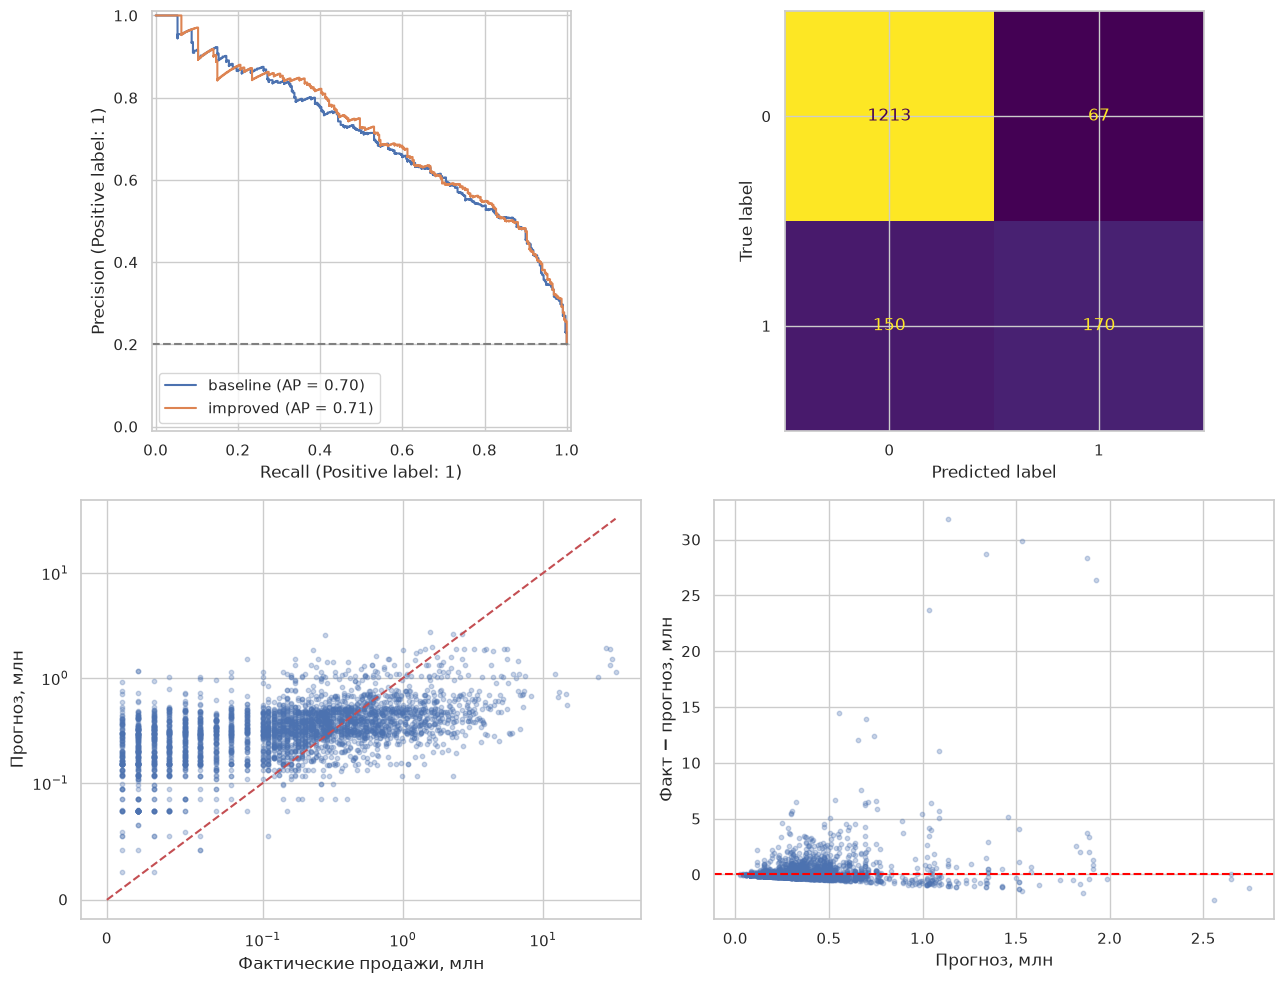

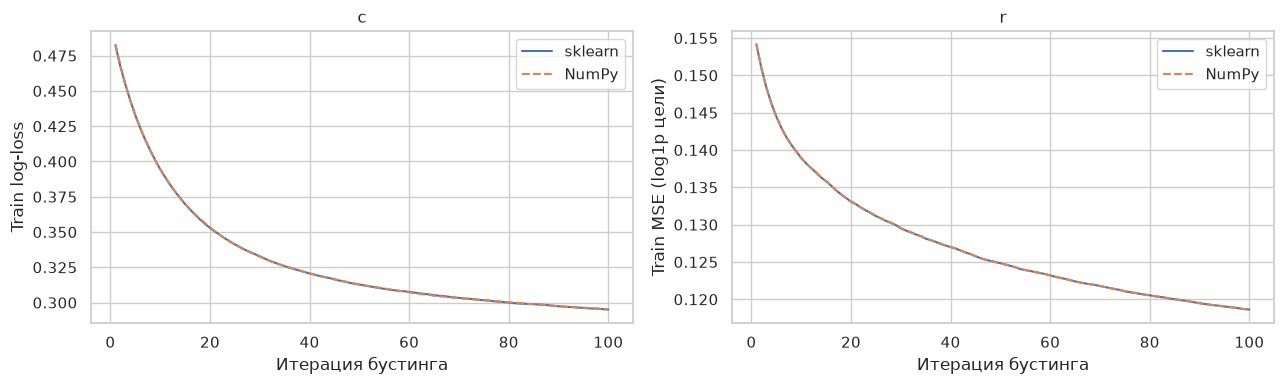

,Важность по снижению нечистоты
num__wishlists_k,0.775593
num__trailer_views_k,0.072488
num__wishlist_price,0.042386
num__has_multiplayer,0.037293
num__wishlist_per_team,0.020089
cat__genre_Shooter,0.008411
num__wishlist_trailer_ratio,0.007328
num__controller_support,0.006446
num__team_size,0.005732
num__file_size_gb,0.005500


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for stage in ["baseline", "improved"]:
    PrecisionRecallDisplay.from_predictions(yc_test, predictions[("c", "sklearn " + stage)][1], name=stage, ax=axes[0, 0])
axes[0, 0].axhline(yc_test.mean(), color="gray", linestyle="--")
ConfusionMatrixDisplay.from_predictions(yc_test, predictions[("c", "sklearn improved")][0], ax=axes[0, 1], colorbar=False)
pred = predictions[("r", "sklearn improved")]
axes[1, 0].scatter(yr_test, pred, alpha=.3, s=10)
axes[1, 0].plot([0, yr_test.max()], [0, yr_test.max()], "r--")
axes[1, 0].set_xscale("symlog", linthresh=.1); axes[1, 0].set_yscale("symlog", linthresh=.1)
axes[1, 0].set(xlabel="Фактические продажи, млн", ylabel="Прогноз, млн")
axes[1, 1].scatter(pred, yr_test.to_numpy()-pred, alpha=.3, s=10)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set(xlabel="Прогноз, млн", ylabel="Факт − прогноз, млн")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task, X, y in [(axes[0], "c", Xc_train, yc_train), (axes[1], "r", Xr_train, yr_train)]:
    model, own_model = improved[task], own_improved[task]
    pipe = model.regressor_ if isinstance(model, TransformedTargetRegressor) else model
    own_pipe = own_model.regressor_ if isinstance(own_model, TransformedTargetRegressor) else own_model
    matrix = pipe[:-1].transform(X)
    target = model.transformer_.transform(y.to_numpy().reshape(-1, 1)).ravel() if isinstance(model, TransformedTargetRegressor) else y.to_numpy()
    boost = pipe.named_steps["model"]
    if task == "c":
        losses = []
        for probability in boost.staged_predict_proba(matrix):
            p = np.clip(probability[:, 1], 1e-15, 1-1e-15)
            losses.append(np.mean(-target*np.log(p)-(1-target)*np.log1p(-p)))
        ylabel = "Train log-loss"
    else:
        losses = [mean_squared_error(target, prediction) for prediction in boost.staged_predict(matrix)]
        ylabel = "Train MSE (log1p цели)" if isinstance(model, TransformedTargetRegressor) else "Train MSE (продажи)"
    ax.plot(np.arange(1, len(losses)+1), losses, label="sklearn")
    own_losses = own_pipe.named_steps["model"].train_loss_[1:]
    ax.plot(np.arange(1, len(own_losses)+1), own_losses, linestyle="--", label="NumPy")
    ax.set(xlabel="Итерация бустинга", ylabel=ylabel, title=task); ax.legend()
plt.tight_layout(); plt.show()
model = improved["c"]
display(pd.Series(model.named_steps["model"].feature_importances_, index=model.named_steps["prep"].get_feature_names_out(),
                  name="Важность по снижению нечистоты").sort_values(ascending=False).head(12).to_frame())

### Выводы по пунктам 3g, 4e и 4j
Численные выводы ниже строятся по фактическим результатам. Отдельно сравниваем улучшение относительно исходного бустинга, собственную модель со sklearn и преимущество над Dummy. Разницу между реализациями нельзя объяснять только совпадением округлённых метрик: выше отдельно проверены последовательные прогнозы, антиградиенты и ньютоновские листья на контролируемых примерах.

Скорость обучения и число итераций действуют совместно; более глубокие деревья могут как улучшать представление взаимодействий, так и переобучаться. Стохастический бустинг уменьшает зависимость от одной обучающей выборки, но не гарантирует улучшения каждого запуска. AP и F1 могут двигаться по-разному из-за фиксированного порога 0.5.

Log1p цели меняет оптимизируемую ошибку и центр прогноза. MAE и RMSE следует рассматривать совместно; отрицательные прогнозы регрессии не обрезались, их число показано в таблицах. Кривые train-loss не доказывают качество на новых данных: его оценивают CV и тест.

Один holdout не доказывает статистическую значимость; последовательный выбор на тех же CV-fold делает CV-оценки оптимистичными. Тест не использовался для повторного подбора. Данные Steam синтетические, продажи исторические и отобраны по наличию продаж. Для внедрения нужны временная проверка, реальные дорелизные признаки и общий горизонт наблюдения.

In [14]:
for task, metric, label in [("c", "AP", "Классификация"), ("r", "MAE", "Регрессия")]:
    tab = metrics[metrics.task == task].set_index("model")
    a, b = tab.loc["sklearn baseline", metric], tab.loc["sklearn improved", metric]
    u, v = tab.loc["numpy baseline", metric], tab.loc["numpy improved", metric]
    gain = b-a if task == "c" else a-b
    own_gain = v-u if task == "c" else u-v
    dummy = tab.loc["Dummy", metric]
    beats_dummy = b > dummy if task == "c" else b < dummy
    display(Markdown(f"**{label}.** Выбрано по CV: `{selected[task]}`. "
        f"sklearn {metric}: {a:.5f} → {b:.5f} (выигрыш {gain:+.5f}); "
        f"NumPy: {u:.5f} → {v:.5f} (выигрыш {own_gain:+.5f}). "
        f"NumPy improved минус sklearn improved: {v-b:+.6f}. "
        f"Dummy: {dummy:.5f}. "
        + ("Улучшенная sklearn-модель превзошла Dummy." if beats_dummy else "Улучшенная sklearn-модель не превзошла Dummy по основной метрике.")
        + (" Перенос улучшений в NumPy дал выигрыш." if own_gain > 0 else " Перенос улучшений не дал выигрыша в NumPy на этом тесте.")))
r = metrics[metrics.task == "r"].set_index("model")
a, b = r.loc["sklearn baseline", "RMSE"], r.loc["sklearn improved", "RMSE"]
display(Markdown(f"**Компромисс регрессии:** RMSE {a:.5f} → {b:.5f} млн копий. "
    + ("Крупные ошибки уменьшились вместе с выбранным улучшением." if b < a else "Улучшение по основной метрике не означает уменьшения крупных ошибок.")))

**Классификация.** Выбрано по CV: `H3 stochastic`. sklearn AP: 0.70419 → 0.71300 (выигрыш +0.00882); NumPy: 0.70419 → 0.71365 (выигрыш +0.00946). NumPy improved минус sklearn improved: +0.000642. Dummy: 0.20000. Улучшенная sklearn-модель превзошла Dummy. Перенос улучшений в NumPy дал выигрыш.

**Регрессия.** Выбрано по CV: `H4 log target`. sklearn MAE: 0.53368 → 0.44855 (выигрыш +0.08513); NumPy: 0.53368 → 0.44855 (выигрыш +0.08513). NumPy improved минус sklearn improved: -0.000000. Dummy: 0.45618. Улучшенная sklearn-модель превзошла Dummy. Перенос улучшений в NumPy дал выигрыш.

**Компромисс регрессии:** RMSE 1.49078 → 1.51109 млн копий. Улучшение по основной метрике не означает уменьшения крупных ошибок.